# 3장 1강: 편향-분산 트레이드오프와 과적합/과소적합 진단

## 실습 목표

이번 실습에서는 **Ames Housing** 데이터를 이용하여 모델 복잡도와 과적합/과소적합의 관계를 확인합니다.

- 모델이 너무 단순할 때 나타나는 **고편향(과소적합)** 상태를 확인합니다.
- 모델이 너무 복잡할 때 나타나는 **고분산(과적합)** 상태를 확인합니다.
- `learning_curve()`를 이용하여 학습곡선을 확인합니다.
- `validation_curve()`를 이용하여 모델 복잡도에 따른 Train / Validation 성능 변화를 확인합니다.
- `train-valid gap`을 이용하여 모델 상태를 진단합니다.
- 진단 결과에 맞는 대응 전략을 선택합니다.

> 이 실습에서는 3장 1강 교안에서 다룬 편향-분산, 학습곡선, 검증곡선, train-valid gap, 과적합/과소적합 대응 전략만 사용합니다.

## 실습 환경 / 데이터

- Python
- pandas
- numpy
- matplotlib
- scikit-learn
- 데이터: `Ames_Housing.csv`

### 분석 목표

주택의 여러 특성을 이용하여 `SalePrice`를 예측하는 회귀 문제입니다.

이번 강의의 목적은 예측 성능 자체를 최대화하는 것이 아니라 **모델 복잡도에 따라 Train / Validation 성능이 어떻게 달라지는지 진단하는 것**입니다.

### 사용할 특성

결측치 처리 자체가 이번 강의의 학습 목표가 아니므로, 결측치가 없는 숫자형 특성 중 일부만 사용합니다.

- `OverallQual`
- `GrLivArea`
- `GarageCars`
- `TotalBsmtSF`
- `1stFlrSF`
- `YearBuilt`

예측 대상은 `SalePrice`입니다.

## 실습 준비

1. Ames Housing 데이터를 불러옵니다.
2. 사용할 특성과 예측 대상을 선택합니다.
3. 결측치가 없는지 확인합니다.
4. 데이터 크기와 기초 통계량을 확인합니다.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import learning_curve, validation_curve

house = pd.read_csv("Ames_Housing.csv")

features = [
    "OverallQual",
    "GrLivArea",
    "GarageCars",
    "TotalBsmtSF",
    "1stFlrSF",
    "YearBuilt"
]

X = house[features]
y = house["SalePrice"]

print("X 크기:", X.shape)
print("y 크기:", y.shape)

print("\n[결측치]")
display(X.isna().sum().to_frame("missing"))

print("\n[기초 통계량]")
display(X.describe())

X 크기: (1460, 6)
y 크기: (1460,)

[결측치]


,missing
OverallQual,0
GrLivArea,0
GarageCars,0
TotalBsmtSF,0
1stFlrSF,0
YearBuilt,0



[기초 통계량]


,OverallQual,GrLivArea,GarageCars,TotalBsmtSF,1stFlrSF,YearBuilt
count,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,6.099315,1515.463699,1.767123,1057.429452,1162.626712,1971.267808
std,1.382997,525.480383,0.747315,438.705324,386.587738,30.202904
min,1.000000,334.000000,0.000000,0.000000,334.000000,1872.000000
25%,5.000000,1129.500000,1.000000,795.750000,882.000000,1954.000000
50%,6.000000,1464.000000,2.000000,991.500000,1087.000000,1973.000000
75%,7.000000,1776.750000,2.000000,1298.250000,1391.250000,2000.000000
max,10.000000,5642.000000,4.000000,6110.000000,4692.000000,2010.000000


---

# 필수 1. 학습곡선으로 과소적합과 과적합 진단

## 배경

학습곡선은 **학습 데이터의 양을 늘려가며 Train score와 Validation score가 어떻게 변하는지 확인하는 그래프**입니다.

이번 문제에서는 같은 Ames Housing 데이터에 대해 두 개의 결정트리를 비교합니다.

- `max_depth=2` → 복잡도가 낮은 모델
- `max_depth=None` → 깊이를 제한하지 않은 복잡한 모델

## 문제 1. `max_depth=2` 모델의 학습곡선을 그리세요.

### 요구사항

1. `DecisionTreeRegressor(max_depth=2, random_state=42)`를 만듭니다.
2. `learning_curve()`를 사용합니다.
3. `cv=5`를 사용합니다.
4. 학습 데이터 비율은 `np.linspace(0.1, 1.0, 6)`을 사용합니다.
5. 각 구간의 Train score와 Validation score 평균을 계산합니다.
6. 두 점수를 하나의 그래프에 표시합니다.
7. 두 곡선이 어디에서 수렴하는지 확인합니다.

### 확인 포인트

- 두 점수가 모두 낮은 수준에서 가까워지는가?
- 모델이 너무 단순한 상태인지 판단할 수 있는가?

[Train Size]
[ 116  327  537  747  957 1168]

[Train R2]
[0.70177277 0.66968877 0.66458113 0.65328922 0.64551293 0.63412113]

[Validation R2]
[0.57778979 0.60045189 0.59401941 0.60051215 0.57435661 0.60237815]

[마지막 지점]
Train      : 0.6341211345629196
Validation : 0.6023781474409343
Gap        : 0.03174298712198531


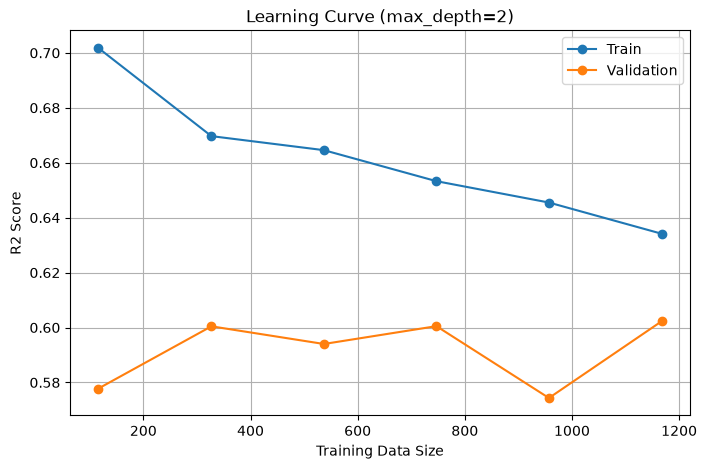

In [2]:
# TODO
# max_depth=2 결정트리의 학습곡선을 그려보세요.

model_depth2 = DecisionTreeRegressor(max_depth=2, random_state=42)

train_sizes, train_scores, validation_scores = learning_curve(
    model_depth2,
    X,
    y,
    train_sizes=np.linspace(0.1, 1.0, 6),
    cv=5,
    scoring="r2"
)

train_mean = train_scores.mean(axis=1)
validation_mean = validation_scores.mean(axis=1)

print("[Train Size]")
print(train_sizes)

print("\n[Train R2]")
print(train_mean)

print("\n[Validation R2]")
print(validation_mean)

print("\n[마지막 지점]")
print("Train      :", train_mean[-1])
print("Validation :", validation_mean[-1])
print("Gap        :", train_mean[-1] - validation_mean[-1])

plt.figure(figsize=(8, 5))

plt.plot(train_sizes, train_mean, marker="o", label="Train")
plt.plot(train_sizes, validation_mean, marker="o", label="Validation")

plt.xlabel("Training Data Size")
plt.ylabel("R2 Score")
plt.title("Learning Curve (max_depth=2)")
plt.legend()
plt.grid()

plt.show()

#### R² : 결정계수
#### R² = 1 : 실제값과 예측값이 일치
#### R² = 0 : 실제 평균만 예측, 충분히 설명하지 못함
#### R²이 1에 가까울수록 모델이 그만큼 데이터에 대한 설명력을 가지고 있다.

#### 학습 샘플 수 116 : Train R²의 평균 0.70 / Validation R²의 평균 0.57
#### -> 판단 : 작은 학습데이터에서 비교적 차이가 큼(0.13)

#### 학습 샘플 수 327 : Train R²의 평균 0.66 / Validation R²의 평균 0.60
#### -> 판단 : Train 데이터 R²는 0.04감소 Validation의 R²는 0.03 상승 -> 격차가 줄어들었다.

#### 학습 샘플 수 537 : Train R²의 평균 0.66 / Validation R²의 평균 0.59
#### -> 판단 : Train R²는 유지 Validation R²는 0.01 감소

#### 학습 샘플 수 1,168 : Train R²의 평균 0.63 / Validation R²의 평균 0.60
#### -> 판단 : 평균 점수 차이가 가장 낮다.

#### 그렇다면 이 표와 그래프를 보고 과소적합 또는 편향의 선호를 알 수 있는가?
#### -> R²값이 Train과 Validation에서 약 0.60정도, 즉 데이터에 대한 파악이 약 60점 정도라고 보인다.
#### -> R²값이 비교적 0.60으로 낮기 때문에 모델이 해당 데이터에 대한 충분한 파악을 하지 못한 과소적합을 의심해 볼 수 있다.
#### 단, R²가 0.60이면 무조건 낮다 <-기준이 없기 때문에 추후 다른 평가지표나 그래프를 통해 근거를 강화해야함.

#### 해석 : 깊이2(max_depth=2)의 결정트리는 최대 Fold의 학습 크기 1,168개에서 Train R²가 0.63, Validation R²가 0.60
#### 두 점수의 차이는 1,168에서 격차가 가장 작았지만 R²이 낮아 과소적합을 의심해야 한다.

#### Q1. `max_depth=2` 모델은 과소적합과 과적합 중 어느 쪽에 더 가깝다고 볼 수 있나요?
#### --> 과소적합에 더 가까움 Train과 Validation의 R²값이 모두 낮았으며 그 간격도 적었다.

**답변:**  
여기에 작성하세요.

## 문제 2. `max_depth=None` 모델의 학습곡선을 그리세요.

### 요구사항

1. `DecisionTreeRegressor(max_depth=None, random_state=42)`를 만듭니다.
2. 필수 1 문제 1과 동일한 방식으로 `learning_curve()`를 사용합니다.
3. Train score와 Validation score를 그래프로 나타냅니다.
4. 두 곡선 사이의 간격을 확인합니다.

### 확인 포인트

- Train score가 매우 높은가?
- Validation score와의 간격이 크게 유지되는가?
- 고분산(과적합) 신호를 확인할 수 있는가?

[Train R2]
[0.999905   0.99996566 0.99985953 0.99984795 0.99982586 0.99976769]

[Validation R2]
[0.58976427 0.70432416 0.71526716 0.66929181 0.6849226  0.7271922 ]

[데이터 양에 따른 Gap]
116 -> 0.4101
327 -> 0.2956
537 -> 0.2846
747 -> 0.3306
957 -> 0.3149
1168 -> 0.2726


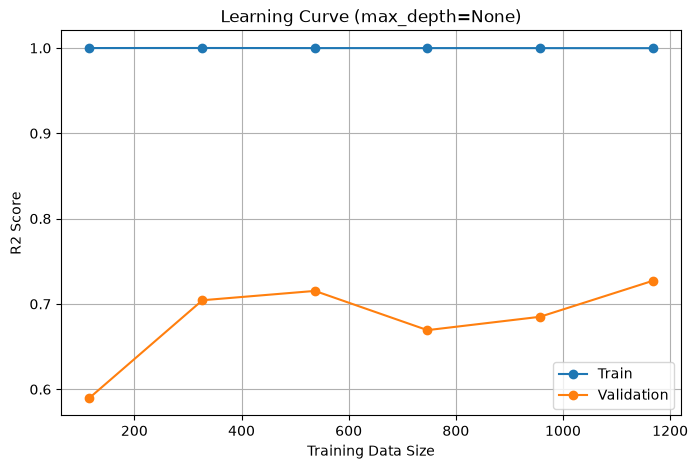

In [3]:
# TODO
# max_depth=None 결정트리의 학습곡선을 그려보세요.

model_full = DecisionTreeRegressor(max_depth=None, random_state=42)

train_sizes, train_scores, validation_scores = learning_curve(
    model_full,
    X,
    y,
    train_sizes=np.linspace(0.1, 1.0, 6),
    cv=5,
    scoring="r2"
)

train_mean = train_scores.mean(axis=1)
validation_mean = validation_scores.mean(axis=1)

print("[Train R2]")
print(train_mean)

print("\n[Validation R2]")
print(validation_mean)

print("\n[데이터 양에 따른 Gap]")
for size, t, v in zip(train_sizes, train_mean, validation_mean):
    print(int(size), "->", round(t - v, 4))

plt.figure(figsize=(8, 5))

plt.plot(train_sizes, train_mean, marker="o", label="Train")
plt.plot(train_sizes, validation_mean, marker="o", label="Validation")

plt.xlabel("Training Data Size")
plt.ylabel("R2 Score")
plt.title("Learning Curve (max_depth=None)")
plt.legend()
plt.grid()

plt.show()

#### 학슴 샘플 수 116 : Train R²의 평균 0.99 / Validation R²의 평균 0.59
#### -> 판단 : 점수차이 0.40

#### 학슴 샘플 수 327 : Train R²의 평균 0.99 / Validation R²의 평균 0.70
#### -> 판단 : 점수차이 0.29

#### 학슴 샘플 수 537 :  Train R²의 평균 0.99 / Validation R²의 평균 0.71
#### -> 판단 : 점수차이 0.28

#### 학슴 샘플 수 1,168 :  Train R²의 평균 0.99 / Validation R²의 평균 0.72
#### -> 판단 : 점수차이 0.27
#### 해당 학습 샘플 수를 선택하여 모델링하는 것이 유리

#### Train R²의 평균 0.99라는 것의 의미 : 매우 작은 제곱오차로 맞추고 있다.(극소한 차이까지 맞춤)

#### Train R²와 Validation R²의 차이가 0.27이라는 것의 의미 : 
#### R²의 차이가 0.27이라고 해서 27%만큼 Validation이 더 틀렸다고 해석하면 안된다.
#### Train(훈련)의 점수는 0.99점이고 Validation(검증)의 점수는 0.27로 차이가 크다는 것은 과적합의 신호

#### 해석 : 깊이 제한이 없는 트리 모델의 경우 Train R²이 거의 1에 가까움
#### 다만 Validation R²은 0.59 ~ 0.72 까지 다양함
#### 학습량 증가에 따른 Validation이 개선의 여지가 보이지만 Train R²과 Validation의 R² 격차를 줄이지 못해
#### 과적합 가능성을 보고 다른 평가지표와 그래프 등을 확인해 보아야 한다.

### Q2. `max_depth=None` 모델에서 데이터를 더 추가하는 것이 도움이 될 가능성이 있는 이유는 무엇인가요?
#### -> 과적합 상태에서는 모델이 현재 데이터를 지나치게 학습을 한 상태로 학습 데이터에만 있는 우연한 특징까지 외운다.
#### -> 데이터가 116개에서 1,168개로 늘어나는 동안 Validation R²는 0.5898 → 0.7272로 올랐고 gap은 0.4101 → 0.2726으로 줄었다. 데이터가 늘어나는 동안 계속 좋아지고 있고 꺾이지 않았으니, 조금 더 올라갈 여지는 남아 있어 보인다. 다만 gap 0.2726은 여전히 크므로 데이터만으로는 부족해 보이며, max_depth 제한을 함께 쓰는 것이 현실적이다.


---

# 필수 2. 검증곡선과 train-valid gap으로 최적 복잡도 확인

## 배경

검증곡선은 **모델의 하이퍼파라미터를 바꿔가며 Train score와 Validation score의 변화를 확인하는 그래프**입니다.

이번 문제에서는 결정트리의 `max_depth`를 바꾸어 모델 복잡도를 조절합니다.

## 문제 1. `max_depth` 검증곡선을 만드세요.

### 요구사항

1. 다음 `max_depth` 후보를 사용합니다.

```python
param_range = [1, 2, 3, 4, 5, 8, 12, 20, None]
```

2. `validation_curve()`를 사용합니다.
3. `cv=5`를 사용합니다.
4. 각 `max_depth`의 Train score와 Validation score 평균을 계산합니다.
5. `gap = train_mean - valid_mean`을 계산합니다.
6. `max_depth`, `train`, `validation`, `gap`을 DataFrame으로 만듭니다.
7. Train / Validation score를 하나의 그래프에 표시합니다.

### 확인 포인트

- 복잡도가 증가할수록 Train score가 어떻게 변하는가?
- Validation score는 어느 지점까지 좋아지고 이후 어떻게 변하는가?
- train-valid gap은 깊이가 커질수록 어떻게 변하는가?

,max_depth,train,validation,gap
0,1,0.454464,0.429791,0.024674
1,2,0.634121,0.602378,0.031743
2,3,0.733594,0.679087,0.054507
3,4,0.811466,0.733510,0.077956
4,5,0.862431,0.755587,0.106844
5,8,0.948189,0.770884,0.177305
6,12,0.989787,0.746059,0.243728
7,20,0.999686,0.735295,0.264391
8,None,0.999768,0.727192,0.272575


Best max_depth: 8
Best Validation R2: 0.7708844071219045
해당 지점의 gap: 0.17730454207985746


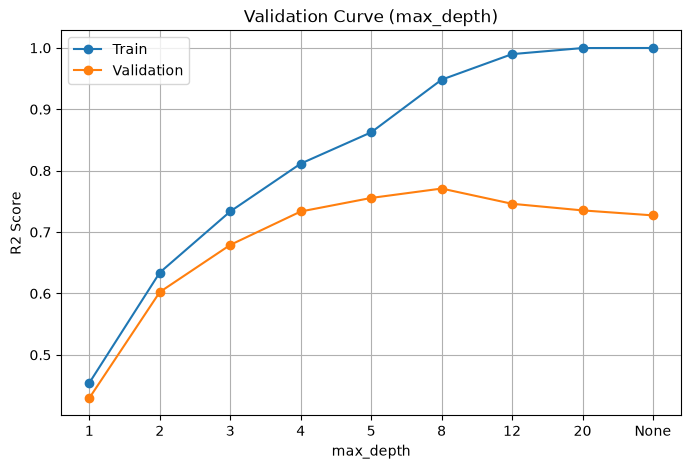

In [ ]:
# TODO
# validation_curve()를 이용해 max_depth별 Train / Validation score와 gap을 확인하세요.

param_range = [1, 2, 3, 4, 5, 8, 12, 20, None]

model = DecisionTreeRegressor(random_state=42)

train_scores, validation_scores = validation_curve(
    model,
    X,
    y,
    param_name="max_depth",
    param_range=param_range,
    cv=5,
    scoring="r2"
)

train_mean = train_scores.mean(axis=1)
validation_mean = validation_scores.mean(axis=1)

gap = train_mean - validation_mean

gap_df = pd.DataFrame({
    "max_depth": [str(p) for p in param_range],
    "train": train_mean,
    "validation": validation_mean,
    "gap": gap
})

display(gap_df)

# Validation 성능이 가장 좋은 지점
best_index = np.argmax(validation_mean)

print("Best max_depth:", param_range[best_index])
print("Best Validation R2:", validation_mean[best_index])
print("해당 지점의 gap:", gap[best_index])

# None은 숫자가 아니므로 위치(index)를 x축으로 사용합니다.
x_pos = np.arange(len(param_range))

plt.figure(figsize=(8, 5))

plt.plot(x_pos, train_mean, marker="o", label="Train")
plt.plot(x_pos, validation_mean, marker="o", label="Validation")

plt.xticks(x_pos, [str(p) for p in param_range])
plt.xlabel("max_depth")
plt.ylabel("R2 Score")
plt.title("Validation Curve (max_depth)")
plt.legend()
plt.grid()

plt.show()

노이즈 발생으로 이상치 처리 반드시 해야한다.(상승곡선 중에서 하락했다가 상승으로 튀어올라갈때)

#### 두 곡선의 목적을 구분
#### 학습곡선과 검증 곡선
#### 학습곡선은 학습자료의 수를 바꾸고 검증곡선 max_depth를 바꾼다.
#### 모델 결과를 유지하려는 핵심 조건은 학습곡선은 트리 깊이 설정, 검증곡선은 데이터와 교차검증 분할
#### 학습곡선의 메인 질문 : 데이터가 늘어나면 늘어날수록 성능이 어떻게 달라지는가?
#### 검증곡선의 메인 질문 : 오차나 변동이 큰 경우 성능이 어떻게 달라지는가?

#### 왜 max_depth 8을 선택할 수 있을까요?
#### -> Train R²와 Validation R²이 비교적 격차가 작으며 Validation R²가 가장 높은 후보를 선택

#### 해석 : 복잡도를 높이면 Train R²는 계속 상승하지만 Validation R²는 깊이 8에서 0.77로 가장 높고 그 이후에 감소, 깊이 1같은 경우 R²값이 Train과 Test에서 모두 낮아 과소적합을 의심해볼 수 있으며 
#### 매우 깊은 depth에서는 Train R²만 좋아져 과적합의 신호를 포착할 수 있다.
#### 우선 가장 효과가 좋았던 depth 8을 검토해볼 수 있다.

### Q3. Validation score가 가장 높은 `max_depth`는 무엇인가요?
#### -> max_depth가 8이 0.77로 가장 높았다.


### Q4. `max_depth`가 매우 커질수록 train-valid gap이 커지는 이유는 무엇인가요?

**답변:**  
#### -> 결정트리가 깊어질수록 학습 데이터의 세부적인 패턴과 노이즈까지 학습을 하려고 하기 때문에
#### Train은 지속적으로 높아지지만 새로운 Validation는 충분히 적응하지 못하기 때문에 유지되거나 낮아질 수 있다.

---

# 과제 1. 모델 상태를 진단하고 대응 전략 선택하기

## 배경

필수 실습에서는 학습곡선과 검증곡선을 이용해 모델의 상태를 확인했습니다.

이번 과제에서는 검증곡선 결과를 이용하여 세 가지 복잡도의 모델 상태를 직접 판단합니다.

> 과제는 필수 실습에서 확인한 결과를 해석하는 수준입니다.

## 문제

다음 세 모델을 확인하세요.

- `max_depth=1`
- `max_depth=8`
- `max_depth=None`

### 요구사항

1. 필수 2에서 만든 `gap_df`에서 세 모델의 Train score, Validation score, gap을 확인합니다.
2. 각 모델을 다음 중 하나로 진단합니다.
   - 과소적합
   - 비교적 적절한 복잡도
   - 과적합
3. 각 모델의 진단 근거를 Train score, Validation score, gap을 이용해 설명합니다.
4. 과소적합 또는 과적합 모델에 대해 교안에서 배운 대응 전략 중 적절한 방향을 하나 이상 작성합니다.

### 확인 포인트

- 점수가 낮고 gap이 작은 경우를 과소적합으로 해석할 수 있는가?
- Train score만 매우 높고 gap이 큰 경우를 과적합으로 해석할 수 있는가?
- Validation score가 높고 gap이 지나치게 크지 않은 지점을 적절한 후보로 볼 수 있는가?
- 진단 후에 대응 전략을 선택했는가?

In [11]:
# TODO
# gap_df에서 max_depth=1, 8, None에 해당하는 결과를 확인하세요.
# gap_df에서 max_depth=1, 8, None에 해당하는 결과를 확인하세요.

check_df = gap_df[gap_df["max_depth"].isin(["1", "8", "None"])]

display(check_df)

for _, row in check_df.iterrows():
    print("max_depth =", row["max_depth"])
    print("  train      :", round(row["train"], 4))
    print("  validation :", round(row["validation"], 4))
    print("  gap        :", round(row["gap"], 4))
    print()

,max_depth,train,validation,gap
0,1,0.454464,0.429791,0.024674
5,8,0.948189,0.770884,0.177305
8,None,0.999768,0.727192,0.272575


max_depth = 1
  train      : 0.4545
  validation : 0.4298
  gap        : 0.0247

max_depth = 8
  train      : 0.9482
  validation : 0.7709
  gap        : 0.1773

max_depth = None
  train      : 0.9998
  validation : 0.7272
  gap        : 0.2726



|max_depth|train|validation|gap|
|---|---|---|---|
|8|0.948189|0.770884|0.177305|
|12|0.989787|0.746059|0.243728|
|20|0.999686|0.735295|0.264391|
|None|0.999768|0.727192|0.272575|

### Q5. 세 모델의 상태를 각각 진단하세요.

| max_depth | 진단 | 근거 |
|---|---|---|
| 1 | 과소적합 | Train 0.4545, Validation 0.4298로 둘 다 낮다. gap은 0.0247로 가장 작다. 학습 데이터조차 못 맞히므로 모델이 단순한 편이다. |
| 8 | 비교적 적절한 복잡도 | Validation 0.7709로 가장 높다. Train 0.9482로 gap 0.1773이지만, 더 깊은 12·20·None보다 작으면서 Validation은 더 높다. |
| None | 과적합 | Validation은 0.7272로 8보다 낮다. gap 0.2726으로 가장 크다. 복잡도를 높혀 데이터 성능이 돌아오지 않는다. |

### Q6. 과소적합 모델과 과적합 모델에 각각 어떤 대응 전략을 사용할 수 있나요?

**답변:**  
-> 과소적합 : 모델을 더 복잡하게 만든다
1. 복잡도를 높이기 위해 max_depth를 늘린다. 실제로 1에서 8로 올리자 Validation이 0.4298 → 0.7709로 크게 올랐다.
2. 특성을 늘리거나 만든다. 설명력 있는 특성을 추가하면 복잡도를 높이는데 도움이 될 수 있다.
3. 규제를 줄인다. min_samples_leaf 같은 제한을 걸어뒀다면 완화한다.
4. 데이터를 더 모으는 것은 효과가 거의 없다. 학습곡선에서 데이터를 10배 늘려도 Validation이 0.5778에서 0.6024로 늘린 데이터에 비해 Validation 값 변화가 적은 편이다.

과적합 : 모델을 더 단순하게 만들거나 데이터를 늘린다
1. 복잡도를 제한한다. max_depth를 8 수준으로 줄이면 Validation이 0.7272 → 0.7709로 오른다. max_depth=8의 Validation 값이 가장 정점에 있다.
2. 규제를 추가한다. min_samples_leaf나 min_samples_split로 지나치게 잘게 쪼개지는 것을 막는다.
3. 데이터를 더 모은다. 학습곡선에서 Validation이 아직 오르는 중이므로 효과를 기대할 수 있다. 다만 간격이 0.2726으로 커서 데이터만으로는 부족해 보인다.
4. 여러 모델을 평균 낸다. 랜덤포레스트처럼 나무를 여러 개 만들어 평균 내면 개별 나무의 과적합이 완화된다.

---

# 실습 마무리

아래 질문에 짧게 답해보세요.

1. 편향이 높은 모델은 일반적으로 과소적합과 과적합 중 어느 상태와 관련이 있나요?
->  편향이 높은 모델은 일반적으로 과소적합과 관련이 있다.

2. 분산이 높은 모델은 일반적으로 어느 상태와 관련이 있나요?
-> 분산이 높은 모델은 일반적으로 과적합과 관련이 있다.

3. 학습곡선에서 Train과 Validation이 낮은 값에서 함께 수렴하면 어떤 상태인가요?
-> 과소적합의 신호

4. Train score는 매우 높지만 Validation score가 낮고 gap이 크다면 어떤 상태인가요?
-> 과적합의 신호

5. 검증곡선에서 Validation score가 가장 높은 지점은 어떤 의미를 가지나요?
-> 현재 후보 중에서 새로운 데이터에 대한 성능이 가장 좋은, 적절한 모델 후보로 선택할 수 있다.

6. 과적합과 과소적합을 진단하지 않고 바로 처방하면 안 되는 이유는 무엇인가요?
-> 과소적합과 과적합은 서로 반대되는 개념
-> 과소적합 모델은 더 단순하게 설계하거나, 과적합 모델은 더 복잡하게 만들면 문제가 커질 수 있다.
-> 따라서 어떤 문제를 해결해야하는지 명확하게 알고 대응 해야한다.
